Huimin Guo

guo.hu@northeastern.edu

NEUID: 002828299

## Prepare data

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from transformers import BertTokenizer, BertForSequenceClassification, Trainer, TrainingArguments
import torch
from torch.utils.data import Dataset
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.utils import shuffle

In [2]:
# read data
df = pd.read_csv("RedNoteComment.tsv", sep='\t')

display(df.head())
# lable 1: Positive, lable 0: Negative

,lable,test1_a
0,1,好看就少人追，都知道追也追不上
1,1,读大学时候有一次坐公交，我一开始用的公交卡，但貌似遇到雾霭天，公交卡不收费，我还傻愣愣拿出手...
2,1,我选择直接吃药店一两块钱的版维
3,0,要看在什么场所。
4,1,很难让人不怀疑他收钱了


In [4]:
# check data type
df.dtypes

lable       int64
test1_a    object
dtype: object

In [5]:
# check missing data
df.isna().sum()

lable      0
test1_a    0
dtype: int64

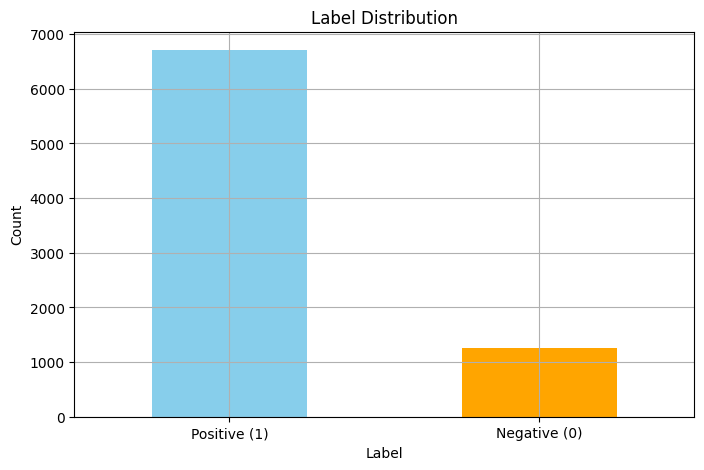

In [7]:
# Label distribution plot
plt.figure(figsize=(8, 5))
df['lable'].value_counts().plot(kind='bar', color=['skyblue', 'orange'])
plt.title('Label Distribution')
plt.xlabel('Label')
plt.ylabel('Count')
plt.xticks(ticks=[0, 1], labels=['Positive (1)', 'Negative (0)'], rotation = 0)
plt.grid(True)
plt.show()

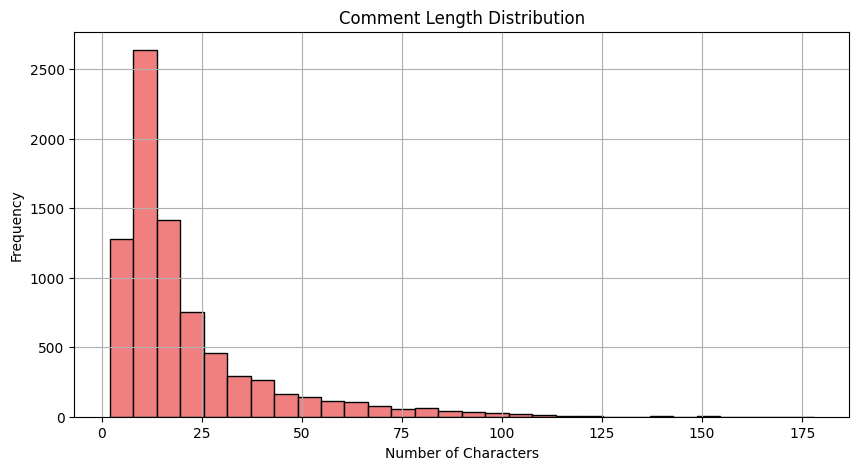

In [8]:
# Comment length distribution plot
comment_lengths = df['test1_a'].astype(str).apply(len)

plt.figure(figsize=(10, 5))
plt.hist(comment_lengths, bins=30, color='lightcoral', edgecolor='black')
plt.title('Comment Length Distribution')
plt.xlabel('Number of Characters')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

In [3]:
# shuffle the data to prevent data regularity
df = shuffle(df, random_state=42).reset_index(drop=True)

# display the first few rows of the shuffled data
df.head()

,lable,test1_a
0,0,这个不搭界的
1,1,！！！！第一次喝太甜了，就再也没喝过了！这个出去吃饭点一下子还可以！这比奶茶香
2,1,笑吐了哈哈哈哈
3,1,如有雷同汗流浃背了
4,1,快来看，我要被吓死了


In [4]:
# spilt data for model
texts = df['test1_a'].tolist()
labels = df['lable'].tolist()

train_texts, val_texts, train_labels, val_labels = train_test_split(texts, labels, test_size=0.2, random_state=42)

In [5]:
tokenizer = BertTokenizer.from_pretrained("bert-base-chinese")

# tokenize data
def tokenize_data(texts, labels, tokenizer, max_length=128):
    encodings = tokenizer(texts, truncation=True, padding=True, max_length=max_length)
    return encodings, labels

# tokenize training data and validation data
train_encodings, train_labels = tokenize_data(train_texts, train_labels, tokenizer)
val_encodings, val_labels = tokenize_data(val_texts, val_labels, tokenizer)

In [6]:
# define a custom dataset class for sentiment analysis
class SentimentDataset(Dataset):
    # initialization method that receives tokenized text data and labels
    def __init__(self, encodings, labels):
        self.encodings = encodings  # store tokenized text encodings
        self.labels = labels        # store corresponding labels

    # return the length of the dataset
    def __len__(self):
        return len(self.labels)  # dataset length is the number of labels

    # retrieve a specific sample from the dataset using an index
    def __getitem__(self, idx):
        # convert each encoding feature (e.g., 'input_ids', 'attention_mask') to PyTorch tensors
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        # convert the label to a tensor and add it to the item dictionary
        item['labels'] = torch.tensor(self.labels[idx])
        return item  # return a dictionary containing the features and label for one sample

# create a training dataset object using the custom dataset class
train_dataset = SentimentDataset(train_encodings, train_labels)

# create a validation dataset object using the custom dataset class
val_dataset = SentimentDataset(val_encodings, val_labels)

## Build Model and Evaluate Performance

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-chinese and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/opt/homebrew/lib/python3.11/site-packages/transformers/training_args.py:1559: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


  0%|          | 0/1197 [00:00<?, ?it/s]

{'loss': 0.3961, 'grad_norm': 2.4470608234405518, 'learning_rate': 4.958228905597327e-05, 'epoch': 0.03}
{'loss': 0.4368, 'grad_norm': 2.328806161880493, 'learning_rate': 4.916457811194654e-05, 'epoch': 0.05}
{'loss': 0.4156, 'grad_norm': 1.655925989151001, 'learning_rate': 4.8746867167919805e-05, 'epoch': 0.08}
{'loss': 0.4294, 'grad_norm': 3.0517847537994385, 'learning_rate': 4.8329156223893066e-05, 'epoch': 0.1}
{'loss': 0.4491, 'grad_norm': 2.2200496196746826, 'learning_rate': 4.791144527986633e-05, 'epoch': 0.13}
{'loss': 0.4373, 'grad_norm': 5.429563522338867, 'learning_rate': 4.74937343358396e-05, 'epoch': 0.15}
{'loss': 0.4747, 'grad_norm': 1.7039930820465088, 'learning_rate': 4.707602339181287e-05, 'epoch': 0.18}
{'loss': 0.533, 'grad_norm': 2.4756875038146973, 'learning_rate': 4.6658312447786136e-05, 'epoch': 0.2}
{'loss': 0.4839, 'grad_norm': 3.3877384662628174, 'learning_rate': 4.62406015037594e-05, 'epoch': 0.23}
{'loss': 0.4587, 'grad_norm': 3.887995481491089, 'learning_r

  0%|          | 0/100 [00:00<?, ?it/s]

{'eval_loss': 0.436562180519104, 'eval_runtime': 8.6093, 'eval_samples_per_second': 185.149, 'eval_steps_per_second': 11.615, 'epoch': 1.0}
{'loss': 0.5078, 'grad_norm': 6.753551483154297, 'learning_rate': 3.329156223893066e-05, 'epoch': 1.0}
{'loss': 0.4963, 'grad_norm': 1.700928807258606, 'learning_rate': 3.287385129490393e-05, 'epoch': 1.03}
{'loss': 0.4196, 'grad_norm': 5.143025875091553, 'learning_rate': 3.24561403508772e-05, 'epoch': 1.05}
{'loss': 0.3657, 'grad_norm': 1.1522443294525146, 'learning_rate': 3.2038429406850464e-05, 'epoch': 1.08}
{'loss': 0.447, 'grad_norm': 1.9010710716247559, 'learning_rate': 3.162071846282373e-05, 'epoch': 1.1}
{'loss': 0.5207, 'grad_norm': 3.1816489696502686, 'learning_rate': 3.120300751879699e-05, 'epoch': 1.13}
{'loss': 0.4311, 'grad_norm': 1.0958847999572754, 'learning_rate': 3.078529657477026e-05, 'epoch': 1.15}
{'loss': 0.3829, 'grad_norm': 3.501342296600342, 'learning_rate': 3.0367585630743527e-05, 'epoch': 1.18}
{'loss': 0.332, 'grad_norm

  0%|          | 0/100 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Evaluation Results: {'eval_loss': 0.4262051284313202, 'eval_runtime': 7.9956, 'eval_samples_per_second': 199.359, 'eval_steps_per_second': 12.507, 'epoch': 3.0}


  0%|          | 0/100 [00:00<?, ?it/s]

accuracy: 0.8438
precision: 0.8446
recall: 0.9985
F1: 0.9151


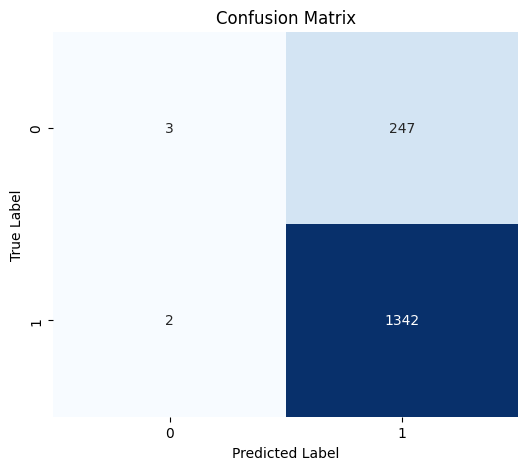

In [13]:
# load Bert model
model = BertForSequenceClassification.from_pretrained("bert-base-chinese", num_labels=2)

training_args = TrainingArguments(
    output_dir='./results',          # directory to save output
    evaluation_strategy="epoch",     # evaluate after each epoch
    save_strategy="epoch",           # save model after each epoch
    per_device_train_batch_size=16,  # batch size per device for training
    per_device_eval_batch_size=16,   # batch size per device for evaluation
    num_train_epochs=3,              # number of training epochs
    logging_dir='./logs',            # directory to save logs
    logging_steps=10,                # frequency of logging steps
    load_best_model_at_end=True      # load the best model at the end of training
)

# use the Trainer API for model training and validation
trainer = Trainer(
    model=model,                         # model to be trained
    args=training_args,                  # training arguments
    train_dataset=train_dataset,         # training dataset
    eval_dataset=val_dataset             # validation dataset
)

# start training
trainer.train()

# evaluate model
results = trainer.evaluate()
print(f"Evaluation Results: {results}")

# compare real lables and predicted one
true_labels = val_labels  # real labels
predictions = trainer.predict(val_dataset).predictions.argmax(-1)

# compute model accuracy, precision, recall, f1
accuracy = accuracy_score(true_labels, predictions)
precision, recall, f1, _ = precision_recall_fscore_support(true_labels, predictions, average='binary')

print(f"accuracy: {accuracy:.4f}")
print(f"precision: {precision:.4f}")
print(f"recall: {recall:.4f}")
print(f"F1: {f1:.4f}")

# compute confusion matrix
cm = confusion_matrix(true_labels, predictions)

# visualize matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

o	Accuracy: The model achieved an accuracy of approximately 82.7%, indicating its ability to correctly classify comments across the two sentiment categories.
o	Precision, Recall, and F1 Score: The precision (85.1%) and recall (95.8%) suggest the model’s strengths in correctly identifying positive cases with a high recall rate, capturing most of the positive sentiments. The F1 score of 90.2% balances these metrics, reflecting robust performance in handling both positive and negative classes.

Confusion Matrix Analysis:
o	True Negatives (TN): 53 samples were correctly classified as negative.
o	False Positives (FP): 221 negative samples were incorrectly classified as positive.
o	False Negatives (FN): 55 positive samples were incorrectly classified as negative.
o	True Positives (TP): 1265 samples were correctly classified as positive.

o	High Precision: The model’s precision is relatively high, meaning that most of the samples it classifies as positive are indeed positive. However, there is a significant number of false positives (221), which slightly affects the precision score.
o	High Recall for Positive Class: The model demonstrates a high recall, particularly for the positive class (1), capturing a substantial number of actual positive samples (1265 / (1265 + 55)), indicating that it is effective at recognizing positive sentiment.
o	Error Pattern – False Positives: The model has a tendency to incorrectly classify negative samples as positive (FP). This suggests that while the model performs well on positive sentiment classification, it struggles to accurately recognize negative sentiment. Improving the model’s ability to distinguish negative sentiment could enhance its overall performance.


In [ ]:
# load Bert model
model = BertForSequenceClassification.from_pretrained("bert-base-chinese", num_labels=2)

training_args = TrainingArguments(
    output_dir='./results',          # directory to save output
    evaluation_strategy="epoch",     # evaluate after each epoch
    save_strategy="epoch",           # save model after each epoch
    per_device_train_batch_size=16,  # batch size per device for training
    per_device_eval_batch_size=16,   # batch size per device for evaluation
    num_train_epochs=4,              # number of training epochs
    logging_dir='./logs',            # directory to save logs
    logging_steps=10,                # frequency of logging steps
    load_best_model_at_end=True      # load the best model at the end of training
)

# use the Trainer API for model training and validation
trainer = Trainer(
    model=model,                         # model to be trained
    args=training_args,                  # training arguments
    train_dataset=train_dataset,         # training dataset
    eval_dataset=val_dataset             # validation dataset
)

# start training
trainer.train()

# evaluate model
results = trainer.evaluate()
print(f"Evaluation Results: {results}")

# compare real lables and predicted one
true_labels = val_labels  # real labels
predictions = trainer.predict(val_dataset).predictions.argmax(-1)

# compute model accuracy, precision, recall, f1
accuracy = accuracy_score(true_labels, predictions)
precision, recall, f1, _ = precision_recall_fscore_support(true_labels, predictions, average='binary')

print(f"accuracy: {accuracy:.4f}")
print(f"precision: {precision:.4f}")
print(f"recall: {recall:.4f}")
print(f"F1: {f1:.4f}")

# compute confusion matrix
cm = confusion_matrix(true_labels, predictions)

# visualize matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-chinese and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/opt/homebrew/lib/python3.11/site-packages/transformers/training_args.py:1559: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


  0%|          | 0/1596 [00:00<?, ?it/s]

{'loss': 0.4121, 'grad_norm': 2.9854466915130615, 'learning_rate': 4.9686716791979956e-05, 'epoch': 0.03}
{'loss': 0.4358, 'grad_norm': 2.2183005809783936, 'learning_rate': 4.93734335839599e-05, 'epoch': 0.05}
